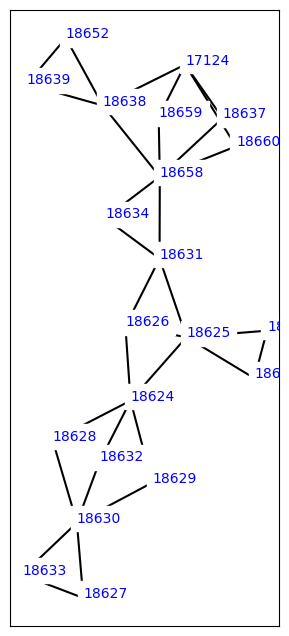

In [ ]:
import openfe
from openfe.utils.atommapping_network_plotting import plot_atommapping_network

system = "JNK1"
ligand_network_path="/path/to/ligand_network.graphml"
# Optional second network to compare against, or None
ligand_network_path_2 = "/path/to/ligand_network.graphml"
with open(ligand_network_path) as f:
    graphml = f.read()

ligand_network = openfe.LigandNetwork.from_graphml(graphml)

fig = plot_atommapping_network(ligand_network)
fig

# Save figure
# fig.savefig(f"{system}/rbfe_network_planning/ligand_network.png", dpi=300, bbox_inches='tight')

1: 18634 - 18631
2: 18629 - 18624
3: 18627 - 18630
4: 18652 - 18639
5: 18624 - 18632
6: 18629 - 18630
7: 18633 - 18630
8: 18628 - 18624
9: 18638 - 18652
10: 18638 - 18639
11: 18631 - 18626
12: 17124 - 18637
13: 17124 - 18659
14: 18624 - 18625
15: 18625 - 18626
16: 18628 - 18630
17: 18635 - 18636
18: 17124 - 18638
19: 18625 - 18631
20: 18660 - 17124
21: 18635 - 18625
22: 18638 - 18658
23: 18630 - 18632
24: 18624 - 18626
25: 18658 - 18631
26: 18637 - 18658
27: 18659 - 18658
28: 18634 - 18658
29: 18660 - 18658
30: 18625 - 18636
31: 18633 - 18627


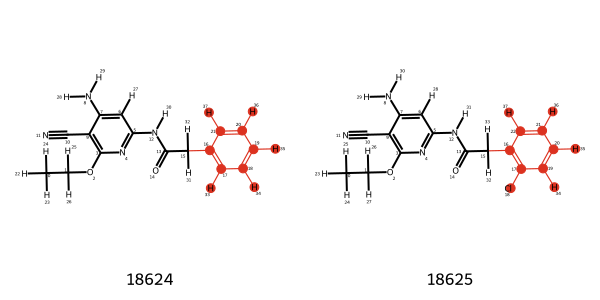

In [8]:
A_name = "18624"
B_name = "18625"
    
count= 0
for edge in ligand_network.edges:
    count += 1
    print(f"{count}: {edge.componentA.name} - {edge.componentB.name}")
        
compoundAtoB = [edge for edge in ligand_network.edges if {edge.componentA.name, edge.componentB.name} == {A_name, B_name}][0] 

compoundAtoB

## Network comparison

For every edge, count the atoms in the transforming region, as coloured in the mapping
drawings:

- **red**: atoms not in the mapping, i.e. destroyed from A or created in B.
- **blue**: mapped atoms that change element.

Hydrogens are counted, as in the drawings. Set `heavy_only = True` to count heavy atoms only.

In [10]:
from pathlib import Path

import openfe
import pandas as pd


def load_network(path: str) -> openfe.LigandNetwork:
    """Load a LigandNetwork from a graphml file."""
    return openfe.LigandNetwork.from_graphml(Path(path).read_text())


def edge_counts(mapping: openfe.LigandAtomMapping, heavy_only: bool = False) -> dict:
    """Count red (created or destroyed) and blue (element change) atoms of one edge."""
    mol_a = mapping.componentA.to_rdkit()
    mol_b = mapping.componentB.to_rdkit()

    def keep(atom) -> bool:
        return not (heavy_only and atom.GetAtomicNum() == 1)

    n_red = sum(keep(mol_a.GetAtomWithIdx(i)) for i in mapping.componentA_unique) + sum(
        keep(mol_b.GetAtomWithIdx(i)) for i in mapping.componentB_unique
    )
    n_blue = 0
    for i, j in mapping.componentA_to_componentB.items():
        atom_a, atom_b = mol_a.GetAtomWithIdx(i), mol_b.GetAtomWithIdx(j)
        if atom_a.GetAtomicNum() != atom_b.GetAtomicNum() and (keep(atom_a) or keep(atom_b)):
            n_blue += 1
    return {
        "ligand_A": mapping.componentA.name,
        "ligand_B": mapping.componentB.name,
        "n_red": n_red,
        "n_blue": n_blue,
        "n_total": n_red + n_blue,
        "score": mapping.annotations.get("score"),
    }


def network_table(
    network: openfe.LigandNetwork, label: str, heavy_only: bool = False
) -> pd.DataFrame:
    """Return one row of red and blue atom counts per edge of a network."""
    rows = [edge_counts(edge, heavy_only) for edge in network.edges]
    table = pd.DataFrame(rows).assign(network=label)
    table["edge"] = [
        " - ".join(sorted((a, b))) for a, b in zip(table.ligand_A, table.ligand_B)
    ]
    return table.sort_values("n_total", ascending=False, ignore_index=True)

In [11]:
heavy_only = False

paths = [p for p in (ligand_network_path, ligand_network_path_2) if p is not None]
# Label each network by its folder name, e.g. transformations_lomap.
tables = {
    Path(p).parent.name: network_table(load_network(p), Path(p).parent.name, heavy_only)
    for p in paths
}
all_edges = pd.concat(tables.values(), ignore_index=True)

summary = (
    all_edges.groupby("network")[["n_red", "n_blue", "n_total"]]
    .agg(["mean", "median", "max"])
    .round(2)
)
summary.insert(0, "n_edges", all_edges.groupby("network").size())
summary

n_edges n_red            n_blue             \
                                           mean median max   mean median max   
network                                                                        
transformations_aligned_kartograf      30  8.03    6.0  26   1.27    1.0   2   
transformations_aligned_lomap          31  7.19    6.0  22   1.39    2.0   2   

                                  n_total             
                                     mean median max  
network                                               
transformations_aligned_kartograf    9.30    8.0  26  
transformations_aligned_lomap        8.58    8.0  22

In [12]:
for label, table in tables.items():
    print(label)
    display(table.drop(columns=["network", "edge"]))

transformations_aligned_lomap


,ligand_A,ligand_B,n_red,n_blue,n_total,score
0,18624,18625,22,0,22,0.272532
1,18624,18626,22,0,22,0.272532
2,18630,18632,15,2,17,0.606531
3,18638,18639,12,1,13,0.606531
4,18624,18632,12,1,13,0.670320
5,18638,18652,11,1,12,0.740818
6,18637,18658,8,2,10,0.606531
7,18634,18658,9,1,10,0.740818
8,18652,18639,7,2,9,0.670320
9,18638,18658,7,2,9,0.606531


transformations_aligned_kartograf


,ligand_A,ligand_B,n_red,n_blue,n_total,score
0,18624,18625,26,0,26,0.272532
1,18624,18626,24,0,24,0.272532
2,18630,18632,17,2,19,0.606531
3,18624,18632,14,1,15,0.670320
4,18638,18652,13,1,14,0.740818
5,18660,18658,13,1,14,0.606531
6,18660,17124,10,2,12,0.606531
7,18634,18658,11,0,11,0.740818
8,18637,18658,10,1,11,0.606531
9,18638,18658,9,1,10,0.606531


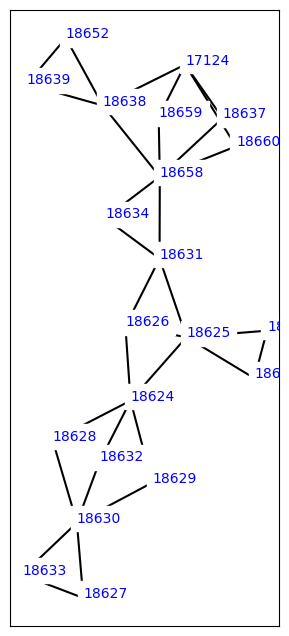

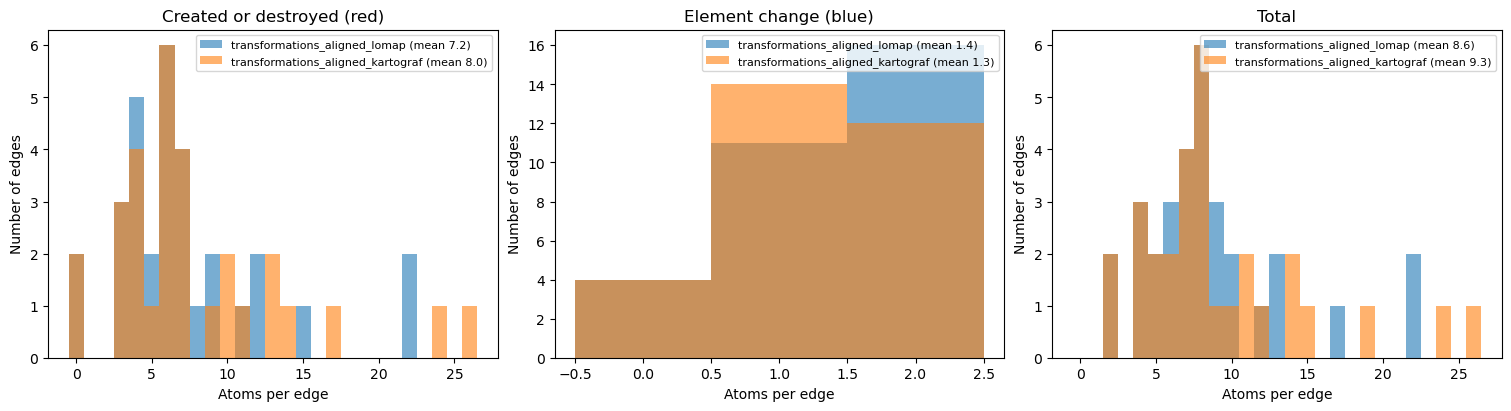

In [13]:
import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(1, 3, figsize=(15, 4), constrained_layout=True)
for ax, column, title in zip(
    axes,
    ["n_red", "n_blue", "n_total"],
    ["Created or destroyed (red)", "Element change (blue)", "Total"],
):
    bins = np.arange(all_edges[column].max() + 2) - 0.5
    for label, table in tables.items():
        ax.hist(table[column], bins=bins, alpha=0.6, label=f"{label} (mean {table[column].mean():.1f})")
    ax.set_title(title)
    ax.set_xlabel("Atoms per edge")
    ax.set_ylabel("Number of edges")
    ax.legend(fontsize=8)
plt.show()